# Flaviviridae glycoproteins: separation of the annotated groups by pairwise similarity

Candidate panel for Figure 1, next to the SCOPe benchmark (panel c). Question: do the pairwise
similarities from ESM3Di's predicted 3Di separate known groups of viral proteins better than
ProstT5's, and how close do they get to 3Di from AlphaFold2 structures? MMseqs2 (amino-acid
alignment only) is the sequence baseline, as in panel c.

**Data.** The 626 E, E1 and E2 envelope glycoproteins of `flaviviridae_trees.ipynb`, with the
groups of Mifsud et al. as six-letter codes (e.g. `E1HPHV`: protein E1, group HPHV). The 13
unclassified sequences (codes ending in `UN`) are left out, since their group is unknown.

**Searches.** All-vs-all, every pair aligned:

| Method | Search |
|---|---|
| ESM3Di, ProstT5 | Foldseek on predicted 3Di + amino acids (the `esm3di foldtree` runs of `flaviviridae_trees.ipynb`) |
| AlphaFold2 | Foldseek on 3Di from the AlphaFold2 structures (same notebook) |
| MMseqs2 | amino-acid alignment, no prefilter (`--prefilter-mode 2`) and no E-value cut-off, like the MMseqs2 baseline of panel c |

**Scores.** Each pair is scored three ways:

- **fident**: the share of identical *amino acids* over the alignment columns (checked against the
  Foldseek alignments: it is not a 3Di identity). FoldTree turns it into the tree distances, so it
  is the score behind the trees of Figure 2. The 3Di only enter through the alignment.
- **bitscore** and **E-value**: the alignment scores Foldseek and MMseqs2 rank hits by; panel c
  (sensitivity up to the first false positive) is based on this ranking.

**Metric.** Every unordered pair is either from the same group or not. The ROC curve lowers a score
threshold and plots the share of same-group pairs above it (true positive rate) against the share of
the other pairs above it (false positive rate). Its area, the AUC, is the chance that a random
same-group pair scores higher than a random other pair (ties count half): 0.5 is no separation, 1 a
perfect one.

**Uncertainty.** Pairs share sequences and are not independent, so the 95% intervals come from
`BOOTSTRAPS` bootstrap samples of the *sequences*; a pair is weighted by how often both of its
sequences were drawn. All methods use the same samples, so differences between methods are paired:
an interval of a difference that excludes 0 means the ranking holds across resampled datasets, even
where the intervals of the methods themselves overlap (they move together from sample to sample).

**Running.** The first run needs the foldtree runs in `OUTPUT_DIR` (not tracked) and MMseqs2 on the
PATH (on the cluster: `module load gcc/11.5.0 mmseqs2/18-8cc5c` before starting Jupyter); later
runs reuse the MMseqs2 output. Writes `results/flaviviridae_group_auc*.csv`,
`results/flaviviridae_group_roc.csv` and `figures/flaviviridae_group_roc.{pdf,png}`.

In [1]:
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np
import pandas as pd

from monophyly import glycoprotein_labels

sys.path.insert(0, "../../../benchmarks")   # shared style of the paper figures
from pub_style import METHOD_COLOURS, MUTED_TEXT, WIDTH_DOUBLE, save_pub, use_pub_style

use_pub_style()

INPUT_DIR = Path("flaviviridae_inputs")
OUTPUT_DIR = Path("/scratch/fweikert/phylogeny/flaviviridae")   # all-vs-all searches (not tracked)
RESULTS_DIR = Path("results")
FIGURE_DIR = Path("figures")
MMSEQS = "mmseqs"
THREADS = 4
BOOTSTRAPS = 200

# Method -> all-vs-all search of the glycoproteins (E, E1 and E2 together)
SEARCHES = {
    "AlphaFold2": OUTPUT_DIR / "af2_fullglyco" / "allvall_1.csv",
    "ESM3Di": OUTPUT_DIR / "esm3di_fullglyco" / "allvall_1.csv",
    "ProstT5": OUTPUT_DIR / "prostt5_fullglyco" / "allvall_1.csv",
    "MMseqs2": OUTPUT_DIR / "mmseqs_fullglyco" / "allvall_1.csv",
}
# Score -> (column of the search output, value of a pair without an alignment); higher is more similar
SCORES = {"fident": ("fident", 0.0), "bitscore": ("bits", 0.0), "E-value": ("evalue", np.inf)}
COLUMNS = ["query", "target", "fident", "alnlen", "mismatch", "gapopen", "qstart", "qend", "tstart", "tend",
           "evalue", "bits"]
# 3Di from structures is the structural reference, drawn like Foldseek in panel c
COLOURS = {**METHOD_COLOURS, "AlphaFold2": METHOD_COLOURS["Foldseek"]}

labels = glycoprotein_labels({p: INPUT_DIR / f"refolded_fullglyco_{p}_aa.fas" for p in ("E", "E1", "E2")})
group = {tip: label[:6] for tip, label in labels.items() if label[4:6] != "UN"}
print(f"{len(group)} of {len(labels)} sequences, {len(set(group.values()))} groups")

613 of 626 sequences, 14 groups


## 1. MMseqs2 all-vs-all search

Every pair is aligned (no prefilter) and every alignment is kept (`-e inf`); the output has the
columns of the Foldseek searches of the foldtree workflow.

In [2]:
mmseqs_out = SEARCHES["MMseqs2"]
fasta = INPUT_DIR / "refolded_fullglyco_aa.fas"
if mmseqs_out.exists():
    print(f"Exists, skipping: {mmseqs_out}")
else:
    mmseqs_out.parent.mkdir(parents=True, exist_ok=True)
    cmd = [MMSEQS, "easy-search", str(fasta), str(fasta), str(mmseqs_out), str(mmseqs_out.parent / "tmp"),
           "--prefilter-mode", "2", "-e", "inf", "--max-seqs", "10000", "--threads", str(THREADS),
           "--format-output", ",".join(COLUMNS[:10] + ["evalue", "bits"])]
    print(" ".join(cmd))
    subprocess.run(cmd, check=True, stdout=subprocess.DEVNULL)

Exists, skipping: /scratch/fweikert/phylogeny/flaviviridae/mmseqs_fullglyco/allvall_1.csv


## 2. Pairs and AUC

One alignment per unordered pair: the hit of the alphabetically first sequence against the second
(as in `flaviviridae_trees.ipynb`), else the reverse hit. A pair without either scores as unrelated
(fident and bitscore 0, E-value infinite).

In [3]:
ids = sorted(group)
pairs = pd.MultiIndex.from_tuples([(a, b) for i, a in enumerate(ids) for b in ids[i + 1:]], names=["a", "b"])
same = np.array([group[a] == group[b] for a, b in pairs])


def pair_scores(path):
    # One row per pair in `pairs` with the columns of SCORES, and the number of pairs without an alignment
    table = pd.read_table(path, header=None, names=COLUMNS)
    for column in ("query", "target"):
        table[column] = table[column].str.replace(".pdb", "", regex=False)
    table = table[table["query"].isin(group) & table["target"].isin(group) & (table["query"] != table["target"])]
    q, t = table["query"].to_numpy(), table["target"].to_numpy()
    table = table.assign(a=np.where(q < t, q, t), b=np.where(q < t, t, q), forward=q < t)
    table = table.sort_values("forward", ascending=False, kind="stable").drop_duplicates(["a", "b"])
    table = table.set_index(["a", "b"]).reindex(pairs)
    n_missing = int(table["fident"].isna().sum())
    return pd.DataFrame({score: table[column].fillna(fill).to_numpy() for score, (column, fill) in SCORES.items()}), n_missing


scores, missing = {}, {}
for method, path in SEARCHES.items():
    scores[method], missing[method] = pair_scores(path)
print(f"{len(pairs)} pairs, {same.sum()} from the same group")
print("Pairs without an alignment:", missing)


def similarity(method, score):
    # Score of every pair, oriented so that higher means more similar
    values = scores[method][score].to_numpy()
    return -values if score == "E-value" else values

187578 pairs, 19870 from the same group
Pairs without an alignment: {'AlphaFold2': 0, 'ESM3Di': 0, 'ProstT5': 0, 'MMseqs2': 0}


In [4]:
def weighted_auc(rank, n_ranks, positive, weights):
    # Mann-Whitney AUC of the positive vs the other pairs; rank orders the values, ties count half
    pos = np.bincount(rank, weights=weights * positive, minlength=n_ranks)
    neg = np.bincount(rank, weights=weights * ~positive, minlength=n_ranks)
    below = np.cumsum(neg) - neg
    return float(np.sum(pos * (below + neg / 2)) / (pos.sum() * neg.sum()))


ranks = {}
for method in SEARCHES:
    for score in SCORES:
        unique, rank = np.unique(similarity(method, score), return_inverse=True)
        ranks[method, score] = rank, len(unique)
auc = {key: weighted_auc(rank, n, same, np.ones(len(rank))) for key, (rank, n) in ranks.items()}

# Bootstrap over sequences; every method and score is evaluated on the same samples
position = {s: i for i, s in enumerate(ids)}
first = np.array([position[a] for a, _ in pairs])
second = np.array([position[b] for _, b in pairs])
rng = np.random.default_rng(0)
boot = {key: np.empty(BOOTSTRAPS) for key in ranks}
for k in range(BOOTSTRAPS):
    counts = rng.multinomial(len(ids), np.full(len(ids), 1 / len(ids)))
    weights = (counts[first] * counts[second]).astype(float)
    for key, (rank, n) in ranks.items():
        boot[key][k] = weighted_auc(rank, n, same, weights)

auc_table = pd.DataFrame([
    {"score": score, "method": method, "AUC": auc[method, score],
     "CI low": np.percentile(boot[method, score], 2.5), "CI high": np.percentile(boot[method, score], 97.5)}
    for score in SCORES for method in SEARCHES
]).set_index(["score", "method"])

COMPARISONS = [("ESM3Di", "ProstT5"), ("AlphaFold2", "ESM3Di"), ("MMseqs2", "ESM3Di"), ("MMseqs2", "AlphaFold2")]
difference_table = pd.DataFrame([
    {"score": score, "difference": f"{a} - {b}", "AUC difference": auc[a, score] - auc[b, score],
     "CI low": np.percentile(boot[a, score] - boot[b, score], 2.5),
     "CI high": np.percentile(boot[a, score] - boot[b, score], 97.5),
     "share > 0": (boot[a, score] > boot[b, score]).mean()}
    for score in SCORES for a, b in COMPARISONS
]).set_index(["score", "difference"])

RESULTS_DIR.mkdir(exist_ok=True)
auc_table.round(4).to_csv(RESULTS_DIR / "flaviviridae_group_auc.csv")
difference_table.round(4).to_csv(RESULTS_DIR / "flaviviridae_group_auc_differences.csv")
display(auc_table["AUC"].unstack("score")[list(SCORES)].loc[list(SEARCHES)].round(3))
display(difference_table.round(3))

score,fident,bitscore,E-value
method,,,
AlphaFold2,0.891,0.918,0.911
ESM3Di,0.866,0.860,0.867
ProstT5,0.842,0.877,0.883
MMseqs2,0.520,0.928,0.929


AUC difference  CI low  CI high  share > 0
score    difference                                                      
fident   ESM3Di - ProstT5               0.025   0.016    0.032      1.000
         AlphaFold2 - ESM3Di            0.024   0.018    0.032      1.000
         MMseqs2 - ESM3Di              -0.346  -0.374   -0.318      0.000
         MMseqs2 - AlphaFold2          -0.371  -0.402   -0.346      0.000
bitscore ESM3Di - ProstT5              -0.016  -0.027   -0.006      0.005
         AlphaFold2 - ESM3Di            0.057   0.041    0.075      1.000
         MMseqs2 - ESM3Di               0.068   0.053    0.081      1.000
         MMseqs2 - AlphaFold2           0.011  -0.006    0.026      0.900
E-value  ESM3Di - ProstT5              -0.016  -0.026   -0.006      0.005
         AlphaFold2 - ESM3Di            0.044   0.030    0.060      1.000
         MMseqs2 - ESM3Di               0.062   0.048    0.076      1.000
         MMseqs2 - AlphaFold2           0.017   0.003    0.033      0.990

### Why MMseqs2 fident fails, and what the alignments look like

Without an E-value cut-off, a local amino-acid alignment of two unrelated proteins is short and can
reach a high identity by chance; Foldseek's 3Di-guided alignments of unrelated pairs are longer.
Median alignment length and fident of the two kinds of pairs:

In [5]:
def alignment_summary(method):
    table = pd.read_table(SEARCHES[method], header=None, names=COLUMNS, usecols=["query", "target", "fident", "alnlen"])
    for column in ("query", "target"):
        table[column] = table[column].str.replace(".pdb", "", regex=False)
    table = table[table["query"].isin(group) & table["target"].isin(group) & (table["query"] < table["target"])]
    kind = np.where(table["query"].map(group) == table["target"].map(group), "same group", "other pairs")
    return table.groupby(kind)[["alnlen", "fident"]].median()


display(pd.concat({method: alignment_summary(method) for method in SEARCHES}).unstack().round(3))

alnlen                 fident           
           other pairs same group other pairs same group
AlphaFold2        97.0      209.0       0.126      0.262
ESM3Di           175.0      243.0       0.126      0.239
ProstT5          155.0      224.0       0.129      0.236
MMseqs2           28.0      183.0       0.324      0.324

## 3. Panels

ROC curves in the style of Figure 1 (method colours and AUC table as in panel c), once for fident
(the FoldTree distance) and once for the E-value (the ranking behind panel c). The curves are saved to
`results/flaviviridae_group_roc.csv`, so a panel can be drawn in `figure1.ipynb` from the CSV alone,
like the other panels.

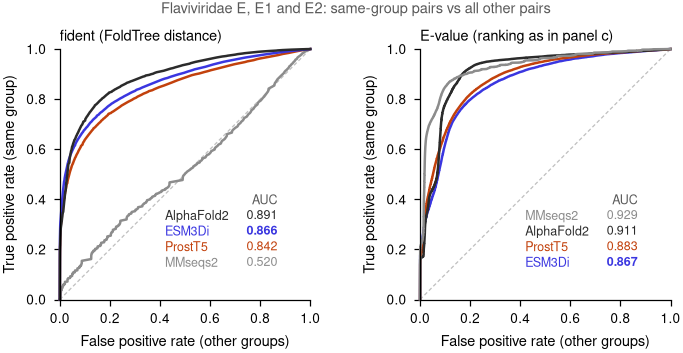

In [6]:
def roc_curve(values, positive):
    # False and true positive rates over all thresholds, most similar first
    order = np.argsort(-values, kind="stable")
    values, positive = values[order], positive[order]
    last = np.r_[np.diff(values) != 0, True]   # one point per distinct threshold
    tp, fp = np.cumsum(positive)[last], np.cumsum(~positive)[last]
    return np.r_[0, fp / fp[-1]], np.r_[0, tp / tp[-1]]


roc = pd.concat([
    pd.DataFrame(dict(zip(("score", "method", "fpr", "tpr"), (score, method, *roc_curve(similarity(method, score), same)))))
    for score in SCORES for method in SEARCHES
])
roc.round(5).to_csv(RESULTS_DIR / "flaviviridae_group_roc.csv", index=False)


def plot_group_roc(ax, roc, auc_table, score, table_xy=(0.42, 0.42)):
    # ROC curve per method for one score, with an AUC table, best method first (as plot_scope_level)
    aucs = auc_table.loc[score, "AUC"].sort_values(ascending=False)
    ax.plot([0, 1], [0, 1], color="0.75", lw=0.6, ls=(0, (3, 2)))
    for method in aucs.index[::-1]:
        curve = roc[(roc["score"] == score) & (roc["method"] == method)]
        ax.plot(curve["fpr"], curve["tpr"], color=COLOURS[method], clip_on=False)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_box_aspect(1)
    ax.xaxis.set_major_locator(ticker.MultipleLocator(0.2))
    ax.yaxis.set_major_locator(ticker.MultipleLocator(0.2))
    ax.set_xlabel("False positive rate (other groups)")
    ax.set_ylabel("True positive rate (same group)")

    value_dx, row_dy = 54, 7.5

    def table_cell(text, dx, row, ha, **kwargs):
        ax.annotate(text, table_xy, xycoords="axes fraction", xytext=(dx, -row_dy * row),
                    textcoords="offset points", ha=ha, va="top", fontsize=6, **kwargs)

    table_cell("AUC", value_dx, 0, "right", color="0.35")
    for row, (method, value) in enumerate(aucs.items(), start=1):
        table_cell(method, 0, row, "left", color=COLOURS[method])
        table_cell(f"{value:.3f}", value_dx, row, "right", color=COLOURS[method],
                   fontweight="bold" if method == "ESM3Di" else "normal")


TITLES = {"fident": "fident (FoldTree distance)", "E-value": "E-value (ranking as in panel c)"}
fig, axes = plt.subplots(1, 2, figsize=(WIDTH_DOUBLE * 2 / 3, WIDTH_DOUBLE / 3), layout="constrained")
for ax, (score, title) in zip(axes, TITLES.items()):
    plot_group_roc(ax, roc, auc_table, score)
    ax.set_title(title)
fig.suptitle("Flaviviridae E, E1 and E2: same-group pairs vs all other pairs", fontsize=7, color=MUTED_TEXT)
save_pub(fig, "flaviviridae_group_roc", FIGURE_DIR)
plt.show()

## 4. Summary

- **fident** (the FoldTree distance): AlphaFold2 > ESM3Di > ProstT5, both gaps significant (paired
  bootstrap). MMseqs2 is near random, because short chance alignments of unrelated proteins reach the
  same identity as related pairs (section 2); this says nothing about the sequence signal itself.
- **bitscore and E-value**: the order of the two predictors reverses (ProstT5 > ESM3Di, significant),
  and MMseqs2 separates the groups best, about as well as AlphaFold2.
- So ESM3Di's advantage over ProstT5 on these proteins holds for the identity FoldTree builds trees
  from, but not for the alignment scores, and the groups are close enough that amino-acid
  alignment alone separates them best.